# Forecasting Student Academic Performance Using Machine Learning

**Module:** Machine Learning  
**Supervisor:** Dr. Muhammad Iqbal                 
**Programme:** Higher Diploma in Data Analytics  
**College:** CCT College Dublin  
**Student:** MONICA VALENCIANO BARAJAS  
**Dataset:** UCI Student Performance – Portuguese Language (student-por.csv)

## Research Question

Which academic, demographic and social factors are most useful for predicting students' final academic performance in Portuguese?

## Project Overview

This project uses the UCI Student Performance dataset to investigate which academic, demographic and social factors are useful for predicting students' final grades in Portuguese.

Three regression models will be developed and compared: Linear Regression, Decision Tree Regressor and Random Forest Regressor.

The final grade (G3) will be used as the target variable, while the previous period grades (G1 and G2) will be excluded from the predictors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Loading

In this section, the dataset will be imported into Python using pandas.

In [3]:
df = pd.read_csv('student-por.csv')

In [4]:
df.head()

,school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3
0,"GP;""F"";18;""U"";""GT3"";""A"";4;4;""at_home"";""teacher..."
1,"GP;""F"";17;""U"";""GT3"";""T"";1;1;""at_home"";""other"";..."
2,"GP;""F"";15;""U"";""LE3"";""T"";1;1;""at_home"";""other"";..."
3,"GP;""F"";15;""U"";""GT3"";""T"";4;2;""health"";""services..."
4,"GP;""F"";16;""U"";""GT3"";""T"";3;3;""other"";""other"";""h..."


In [5]:
df = pd.read_csv('student-por.csv', sep=';')

In [6]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


The dataset is imported using the pandas read_csv() function. The parameter sep=';' is included because the CSV file uses semicolons to separate the columns. This ensures that each variable is correctly recognised as a separate column.

### 2. Dataset Overview

In this section, the dimensions of the dataset are examined to understand how many student records and variables are available for the analysis.

In [7]:
df.shape

(649, 33)

### 3. Dataset Variables

The dataset contains several variables describing students' demographic characteristics, family backgrounds, school-related information and academic performance. The column names are examined to understand the information available for the analysis.

In [9]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

### 4. Data Types

In this section, the data types of each variable are examined to identify numerical and categorical columns and understand how the dataset is structured.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

### 5. Missing Values Check

A missing values check is performed to identify whether any variables contain incomplete records that could affect the data preparation and machine learning process.

In [12]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

**Missing Values Analysis**

The missing values check shows that all 33 variables contain 0 missing values. Each variable has 649 non-null records. 

### 6. Descriptive Statistics

Descriptive statistics are used to examine the numerical variables in the dataset. This provides an overview of their distributions, central values and variability.

In [14]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


**Descriptive Statistics Analysis**

The descriptive statistics show that the dataset contains 649 students, with an average age of approximately 16.7 years.

The average number of absences is 3.54, while the maximum is 32, indicating variation in student attendance.

The average final grade (G3) is approximately 11.91 out of 20. The mean grades increase slightly across the three academic periods.

These results provide an initial understanding of the dataset and help identify variables that may be relevant to the prediction of final academic performance.

### 7.Categorical Variables Exploration

The categorical variables are examined to identify their unique categories before applying LabelEncoder during the data preparation stage.

In [19]:
df['school'].unique()

<ArrowStringArray>
['GP', 'MS']
Length: 2, dtype: str

In [20]:
df['sex'].unique()

<ArrowStringArray>
['F', 'M']
Length: 2, dtype: str

In [21]:
df['address'].unique()

<ArrowStringArray>
['U', 'R']
Length: 2, dtype: str

In [22]:
df['famsize'].unique()

<ArrowStringArray>
['GT3', 'LE3']
Length: 2, dtype: str

In [23]:
df['Pstatus'].unique()

<ArrowStringArray>
['A', 'T']
Length: 2, dtype: str

In [24]:
df['Mjob'].unique()

<ArrowStringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str

In [26]:
df['Fjob'].unique()

<ArrowStringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str

In [27]:
df['reason'].unique()

<ArrowStringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str

In [29]:
df['guardian'].unique()

<ArrowStringArray>
['mother', 'father', 'other']
Length: 3, dtype: str

In [30]:
df['schoolsup'].unique()

<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str

The remaining categorical variables describe different aspects of students' educational support, family environment and personal circumstances. These include additional school support, family support, paid classes, extracurricular activities, nursery attendance, interest in higher education, internet access and romantic relationships.

These variables provide additional information that may help investigate factors associated with students' final academic performance.

### 8.Target Variable Exploration

The target variable for this project is G3, which represents the students' final grade in Portuguese. This variable will be used to predict students' final academic performance using Machine Learning regression models.

In [32]:
df['G3'].describe()

count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

The descriptive statistics show that the dataset contains 649 students. The average final grade (G3) is approximately 11.91 out of 20, while the median is 12. The grades range from 0 to 19, with a standard deviation of approximately 3.23. This indicates that students' final academic performance varies across the dataset.

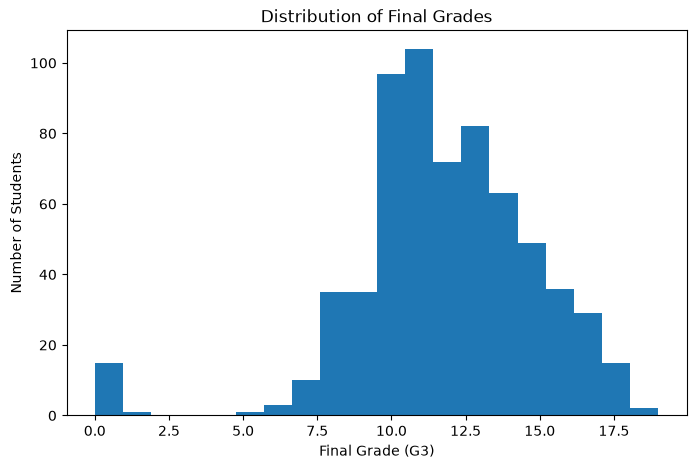

In [34]:
plt.figure(figsize=(8, 5))
plt.hist(df['G3'], bins=20)
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.title('Distribution of Final Grades')
plt.show()

The histogram shows the distribution of students' final grades (G3). Most students achieved grades between approximately 10 and 14, with the highest concentration around 10–11. The frequency of students generally decreases towards the higher grades.

A small number of students received a grade of 0. However, the reason for these results cannot be determined from the available data.

Overall, the histogram indicates variation in students' final academic performance, making G3 a suitable numerical target variable for regression analysis.

In [35]:
X = df.drop(['G1', 'G2', 'G3'], axis=1)

In [37]:
y = df['G3']

In [38]:
print(X.shape)
print(y.shape)

(649, 30)
(649,)


The dataset was divided into predictor variables (X) and the target variable (y). The predictor dataset contains 649 records and 30 features, while the target variable contains 649 final grades (G3). The variables G1 and G2 were excluded to avoid using previous academic grades as predictors.

### 10. Encoding Categorical Variables

In [40]:
from sklearn.preprocessing import LabelEncoder

In [41]:
X.select_dtypes(include='str').columns

Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')

Machine Learning models require numerical input data. However, the dataset contains categorical variables represented as text.
The LabelEncoder method from Scikit-learn will be used to convert these categorical values into numerical labels.
First, the categorical columns were identified to distinguish them from the numerical variables. Only the categorical variables will require encoding.
This preparation step will allow the dataset to be used by the selected Machine Learning regression models.

### 11. Train-Test Split

In [42]:
from sklearn.model_selection import train_test_split

In [88]:
### 0.05
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42)

In [89]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(616, 30)
(33, 30)
(616,)
(33,)


The dataset was divided into training and testing sets using the train_test_split method from Scikit-learn.
The first split uses 95% of the data for training and 5% for testing. The training set contains 616 students, while the testing set contains 33 students.
The random_state=42 parameter ensures that the same data split can be reproduced when the code is executed again.
The training data will be used to build the Machine Learning models, while the testing data will be used to evaluate their predictive performance.

### 12. Encoding Categorical Variables

Categorical variables are represented as text and need to be converted into numerical values before training the Machine Learning models.
The LabelEncoder method from Scikit-learn is used to transform categorical values into numerical labels.
The encoder is fitted using the training data and then applied to the testing data using the same encoding. This prevents information from the testing set from being used during the fitting process.

In [90]:
categorical_columns = X.select_dtypes(include='str').columns

In [91]:
le = LabelEncoder()

X_train['school'] = le.fit_transform(X_train['school'])
X_test['school'] = le.transform(X_test['school'])

In [92]:
print(X_train['school'].unique())

[1 0]


In [93]:
le = LabelEncoder()

X_train['sex'] = le.fit_transform(X_train['sex'])
X_test['sex'] = le.transform(X_test['sex'])

In [94]:
print(X_train['sex'].unique())

[0 1]


In [95]:
le = LabelEncoder()

X_train['address'] = le.fit_transform(X_train['address'])
X_test['address'] = le.transform(X_test['address'])

In [96]:
print(X_train['address'].unique())

[0 1]


In [97]:
le = LabelEncoder()

X_train['famsize'] = le.fit_transform(X_train['famsize'])
X_test['famsize'] = le.transform(X_test['famsize'])

In [98]:
print(X_train['famsize'].unique())

[0 1]


In [99]:
le = LabelEncoder()

X_train['Pstatus'] = le.fit_transform(X_train['Pstatus'])
X_test['Pstatus'] = le.transform(X_test['Pstatus'])

In [100]:
print(X_train['Pstatus'].unique())

[1 0]


In [101]:
le = LabelEncoder()

X_train['Mjob'] = le.fit_transform(X_train['Mjob'])
X_test['Mjob'] = le.transform(X_test['Mjob'])

In [102]:
print(X_train['Mjob'].unique())

[0 2 3 4 1]


In [103]:
le = LabelEncoder()

X_train['Fjob'] = le.fit_transform(X_train['Fjob'])
X_test['Fjob'] = le.transform(X_test['Fjob'])

In [104]:
print(X_train['Fjob'].unique())

[2 3 4 0 1]


In [105]:
le = LabelEncoder()

X_train['reason'] = le.fit_transform(X_train['reason'])
X_test['reason'] = le.transform(X_test['reason'])

In [106]:
print(X_train['reason'].unique())

[0 1 3 2]


In [107]:
le = LabelEncoder()

X_train['guardian'] = le.fit_transform(X_train['guardian'])
X_test['guardian'] = le.transform(X_test['guardian'])

In [108]:
print(X_train['guardian'].unique())

[0 1 2]


In [109]:
le = LabelEncoder()

X_train['schoolsup'] = le.fit_transform(X_train['schoolsup'])
X_test['schoolsup'] = le.transform(X_test['schoolsup'])

In [110]:
print(X_train['schoolsup'].unique())

[1 0]


In [111]:
le = LabelEncoder()

X_train['famsup'] = le.fit_transform(X_train['famsup'])
X_test['famsup'] = le.transform(X_test['famsup'])

In [112]:
print(X_train['famsup'].unique())

[1 0]


In [113]:
le = LabelEncoder()

X_train['paid'] = le.fit_transform(X_train['paid'])
X_test['paid'] = le.transform(X_test['paid'])

In [114]:
print(X_train['paid'].unique())

[0 1]


In [115]:
le = LabelEncoder()

X_train['activities'] = le.fit_transform(X_train['activities'])
X_test['activities'] = le.transform(X_test['activities'])

In [116]:
print(X_train['activities'].unique())

[0 1]


In [117]:
le = LabelEncoder()

X_train['nursery'] = le.fit_transform(X_train['nursery'])
X_test['nursery'] = le.transform(X_test['nursery'])

In [118]:
print(X_train['nursery'].unique())

[1 0]


In [119]:
le = LabelEncoder()

X_train['higher'] = le.fit_transform(X_train['higher'])
X_test['higher'] = le.transform(X_test['higher'])

In [120]:
print(X_train['higher'].unique())

[1 0]


In [121]:
le = LabelEncoder()

X_train['internet'] = le.fit_transform(X_train['internet'])
X_test['internet'] = le.transform(X_test['internet'])

In [122]:
print(X_train['internet'].unique())

[0 1]


In [123]:
le = LabelEncoder()

X_train['romantic'] = le.fit_transform(X_train['romantic'])
X_test['romantic'] = le.transform(X_test['romantic'])

In [124]:
print(X_train['romantic'].unique())

[0 1]


Categorical variables contain text values and need to be converted into numerical values before they can be used by Machine Learning models.
The `LabelEncoder` method was used to encode the 17 categorical variables. The encoder was fitted on the training data and then applied to the testing data to maintain consistent numerical labels.
This process prepares the categorical features for the Machine Learning models.

In [125]:
print(X_train.dtypes)

school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
dtype: object


The data types were checked after encoding to confirm that all 30 predictor variables were numerical. No categorical text columns remained in the training dataset.

In [127]:
### 0.15
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42)

In [128]:
print(X_train_15.shape)
print(X_test_15.shape)
print(y_train_15.shape)
print(y_test_15.shape)

(551, 30)
(98, 30)
(551,)
(98,)


In [129]:
le = LabelEncoder()

X_train_15['school'] = le.fit_transform(X_train_15['school'])
X_test_15['school'] = le.transform(X_test_15['school'])

In [130]:
print(X_train_15['school'].unique())

[0 1]


In [131]:
le = LabelEncoder()

X_train_15['sex'] = le.fit_transform(X_train_15['sex'])
X_test_15['sex'] = le.transform(X_test_15['sex'])

In [132]:
print(X_train_15['sex'].unique())

[1 0]


In [133]:
le = LabelEncoder()

X_train_15['address'] = le.fit_transform(X_train_15['address'])
X_test_15['address'] = le.transform(X_test_15['address'])

In [134]:
print(X_train_15['address'].unique())

[0 1]


In [135]:
le = LabelEncoder()

X_train_15['famsize'] = le.fit_transform(X_train_15['famsize'])
X_test_15['famsize'] = le.transform(X_test_15['famsize'])

In [136]:
print(X_train_15['famsize'].unique())

[1 0]


In [137]:
le = LabelEncoder()

X_train_15['Pstatus'] = le.fit_transform(X_train_15['Pstatus'])
X_test_15['Pstatus'] = le.transform(X_test_15['Pstatus'])